# クリッパ

入力を決めた範囲の中に**制限**して、はみ出した部分を切り取る回路です。大きすぎる入力から次の回路(マイコンの入力など)を守る、ギターの音をわざとひずませる(ディストーション)、といった使い方をします。

この回では、ハードクリッパ、ソフトクリッパ、切り取ったことで生まれる**高調波**(ひずみ)、の 3 つを見ます。

## 回路

![ダイオードクリッパ](03_clipper/circuit.svg)

入力から抵抗 R を通った点(出力)に、2 つのダイオードをつなぎます。$D_1$ は電池 $V_H$ へ、$D_2$ は向きを逆にして電池 $V_L$ へつながっています。電池とグランドは、Mimic でいえば Vref を基準にした電圧です。

- 出力が $V_H$ + ダイオードの順電圧(約 0.6 V)を超えようとすると、$D_1$ に電流が流れて、出力はそこで止まります。
- 出力が $V_L$ − 約 0.6 V より下がろうとすると、$D_2$ に電流が流れて止まります。
- そのあいだでは、どちらのダイオードにも電流が流れないので、出力 = 入力です。

## 原理

制限の電圧を upper と lower とすると:

| 入力 | 出力 |
|---|---|
| upper より高い | upper |
| lower と upper のあいだ | 入力のまま |
| lower より低い | lower |

ダイオードが理想的(ある電圧でいきなり電流が流れる)なら、折れ線の**ハードクリッパ**になります。実際のダイオードの電流は電圧に対して指数関数的に増えるので、角が丸くなって、出力はなめらかに制限に近づきます。これが**ソフトクリッパ**です。オペアンプを使うとハードに近い特性、ダイオードだけだとソフトな特性になります。

![クリッパの入出力特性(模式図)](03_clipper/response.svg)

**高調波**:正弦波の山を切り取ると、波形は正弦波ではなくなります。正弦波でない周期的な波形は、元の周波数(基本波)の 2 倍、3 倍、… の周波数の正弦波(**高調波**)を足し合わせたものになっています。上下を同じだけ切り取ると、奇数倍(3 倍、5 倍、…)の高調波が出ます。角が鋭いハードクリッパほど、高い次数の高調波が多く出ます。

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.clipper(upper, lower)` | `mimic.setClipper(upper, lower)` | ハードクリッパ。upper = $V_H$ + 0.6 V、lower = $V_L$ − 0.6 V(理想のダイオード) |
| `lab.mimic.soft_clipper(upper, lower)` | `mimic.setSoftClipper(upper, lower)` | ソフトクリッパ。中心 = (upper + lower) / 2 でゲイン 1、中心から制限までの距離の 1.5 倍で制限に届く(3 次式) |

例:upper = 3.0 V、lower = 2.0 V(Vref ± 0.5 V)の回路は、ダイオードの順電圧を 0.6 V とすると、$V_H$ = 2.4 V、$V_L$ = 2.6 V の電池にあたります。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, fit_sine

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261125)

波形(左)と、入出力特性(右:CH1 を横軸、CH2 を縦軸にした点)を並べて描く関数です。

In [2]:
def scope_xy(t, ch1, ch2, label="output", xlim=None):
    # Left: the oscilloscope; right: the input-output characteristic (CH1 across, CH2 up)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
    ax1.plot(t * 1e3, ch1, label="CH1: input")
    ax1.plot(t * 1e3, ch2, label=f"CH2: {label}")
    if xlim:
        ax1.set_xlim(*xlim)
    ax1.set_ylim(-0.2, 5.2)
    ax1.set_xlabel("Time [ms]")
    ax1.set_ylabel("Voltage [V]")
    ax1.grid(True)
    ax1.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False)
    ax2.plot(ch1, ch2, ".-", lw=0.5, ms=2, color="C2")   # thin lines show the transitions
    ax2.set_xlim(0, 5)
    ax2.set_ylim(-0.2, 5.2)
    ax2.set_aspect("equal")
    ax2.set_xlabel("CH1: input [V]")
    ax2.set_ylabel("CH2: output [V]")
    ax2.grid(True)
    fig.tight_layout()
    plt.show()

## 実験 1:ハードクリッパ

50 Hz、振幅 1 V の正弦波を、upper = 3.0 V、lower = 2.0 V のハードクリッパに入れます。山と谷が 3.0 V と 2.0 V で平らに切り取られるはずです。

output: 1.992 - 2.997 V (limits 2.0 - 3.0 V)


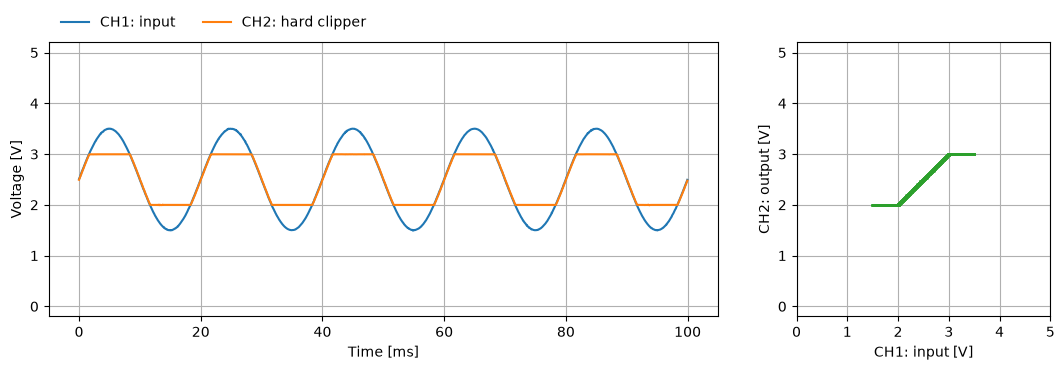

In [3]:
lab.fg.sine(50, 1.0)
lab.mimic.clipper(3.0, 2.0)
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s
print(f"output: {ch2.min():.3f} - {ch2.max():.3f} V (limits 2.0 - 3.0 V)")
scope_xy(t, ch1, ch2, "hard clipper")

入出力特性(右)は、2.0〜3.0 V のあいだは傾き 1 の直線(出力 = 入力)で、その外は水平の折れ線です。

## 実験 2:ソフトクリッパ

同じ入力を、同じ制限のソフトクリッパに入れます。

output: 1.997 - 2.998 V (limits 2.0 - 3.0 V)


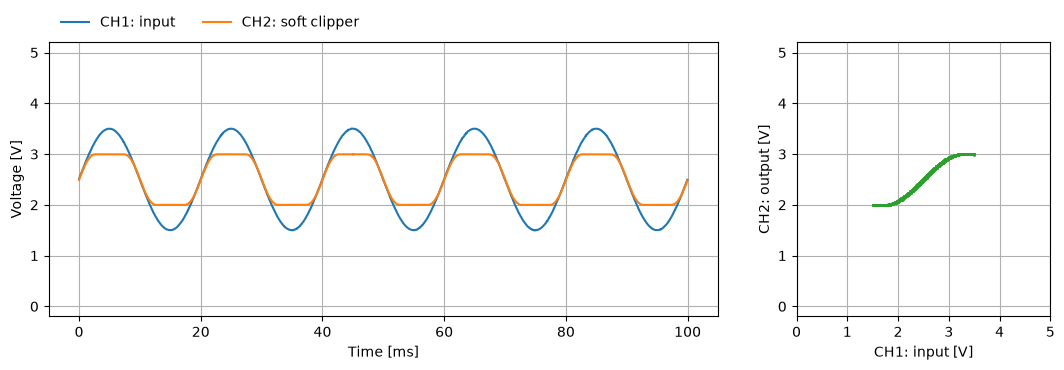

In [4]:
lab.mimic.soft_clipper(3.0, 2.0)
t, ch1, ch2 = lab.scope.capture(2000)
print(f"output: {ch2.min():.3f} - {ch2.max():.3f} V (limits 2.0 - 3.0 V)")
scope_xy(t, ch1, ch2, "soft clipper")

山が丸くなり、なめらかに 3.0 V と 2.0 V に近づきます。入出力特性も、角のないなめらかな曲線です。中心(2.5 V)のまわりでは傾きが 1 で、入力が小さいうちは、ほとんどひずみません。

## 実験 3:高調波を測る

100 Hz、振幅 1 V の正弦波を、入力そのまま、ハードクリッパ、ソフトクリッパで取り込み、それぞれの高調波の大きさを比べます。取り込む 0.1 秒にちょうど 10 周期が入るので、FFT(高速フーリエ変換)で、基本波(100 Hz)と 2〜9 倍の高調波の振幅を取り出せます。

ひずみの大きさの目安として、**全高調波ひずみ率**(THD:高調波の振幅の 2 乗和の平方根 ÷ 基本波の振幅)も計算します。

input: fundamental 1.000 V, 3rd   0.1 mV, 5th   0.1 mV, THD  0.06 %
hard : fundamental 0.607 V, 3rd 137.8 mV, 5th  27.9 mV, THD 23.31 %
soft : fundamental 0.597 V, 3rd 116.6 mV, 5th  16.4 mV, THD 19.74 %


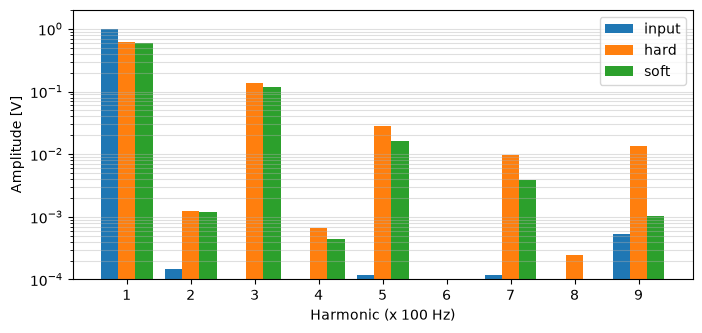

In [5]:
def harmonics(v, f0, fs, n=9):
    # Amplitudes of the fundamental (f0) and its harmonics up to n x f0
    spec = np.abs(np.fft.rfft(v - v.mean())) * 2 / len(v)
    k = int(round(f0 * len(v) / fs))
    return spec[k * np.arange(1, n + 1)]

lab.fg.sine(100, 1.0)
amps = {}
lab.mimic.bypass()
t, ch1, ch2 = lab.scope.capture(2000)
fs = 1 / (t[1] - t[0])
amps["input"] = harmonics(ch2, 100, fs)
lab.mimic.clipper(3.0, 2.0)
t, ch1, ch2 = lab.scope.capture(2000)
amps["hard"] = harmonics(ch2, 100, fs)
lab.mimic.soft_clipper(3.0, 2.0)
t, ch1, ch2 = lab.scope.capture(2000)
amps["soft"] = harmonics(ch2, 100, fs)

for name, a in amps.items():
    thd = np.sqrt(np.sum(a[1:] ** 2)) / a[0]
    print(f"{name:5s}: fundamental {a[0]:.3f} V, 3rd {a[2] * 1e3:5.1f} mV, 5th {a[4] * 1e3:5.1f} mV, THD {thd * 100:5.2f} %")

fig, ax = plt.subplots(figsize=(8, 3.5))
n = np.arange(1, 10)
for i, (name, a) in enumerate(amps.items()):
    ax.bar(n + (i - 1) * 0.27, a, width=0.27, label=name)
ax.set_yscale("log")
ax.set_ylim(1e-4, 2)
ax.set_xticks(n)
ax.set_xlabel("Harmonic (x 100 Hz)")
ax.set_ylabel("Amplitude [V]")
ax.grid(True, axis="y", which="both", alpha=0.4)
ax.legend()
plt.show()

入力そのままでは、高調波は小さく(数 mV 以下、信号発生器と測定のひずみ)、ほとんど基本波だけです。クリッパを通すと、3 倍、5 倍、7 倍、9 倍の**奇数次**の高調波が大きく現れます。ソフトクリッパは、ハードクリッパより高い次数(5 倍、7 倍、9 倍)の高調波がずっと小さく、THD も小さくなります(計算ではハード 23 %、ソフト 20 %)。耳で聞くと、ソフトのほうが「やわらかい」ひずみの音になります。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 振幅を変える(ソフトクリッパ)

ソフトクリッパ(3.0 V / 2.0 V)に入れる正弦波の振幅を変えて、ひずみ率を見ます。
<details><summary>ヒント</summary>

`AMP` を 0.1 → 0.3 → 0.5 → 0.75 → 1.0 → 1.5 と変えてみましょう。振幅が小さいうちは中心の直線に近い部分しか使わないので、THD は小さく、波形もほぼ正弦波です。振幅が大きくなるほど THD が増え、1.5 V では平らな部分が長くなって、方形波に近づきます。

</details>

THD 1.48 %, output 2.213 - 2.784 V


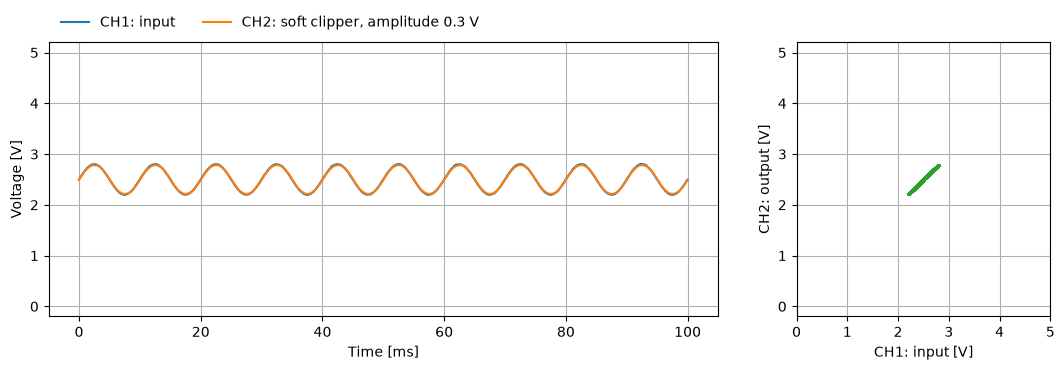

In [6]:
AMP = 0.3   # [V]

lab.fg.sine(100, AMP)
lab.mimic.soft_clipper(3.0, 2.0)
t, ch1, ch2 = lab.scope.capture(2000)
a = harmonics(ch2, 100, 1 / (t[1] - t[0]))
print(f"THD {np.sqrt(np.sum(a[1:] ** 2)) / a[0] * 100:.2f} %, output {ch2.min():.3f} - {ch2.max():.3f} V")
scope_xy(t, ch1, ch2, f"soft clipper, amplitude {AMP} V")

### 2. 上下で違う制限

上と下の制限を中心からずらして、片側だけを切り取ります。高調波はどう変わるでしょうか。
<details><summary>ヒント</summary>

`LOWER` を 2.0 → 1.8 → 1.5 と変えてみましょう(upper は 3.0 V のまま)。1.5 V では、振幅 1 V の正弦波(1.5〜3.5 V)の谷は切り取られず、山だけが切り取られます。上下が非対称になると、**偶数次**(2 倍、4 倍)の高調波が現れ、出力の平均(直流)も Vref からずれます。

</details>

2nd 1.2 mV, 3rd 137.7 mV, mean 2.498 V


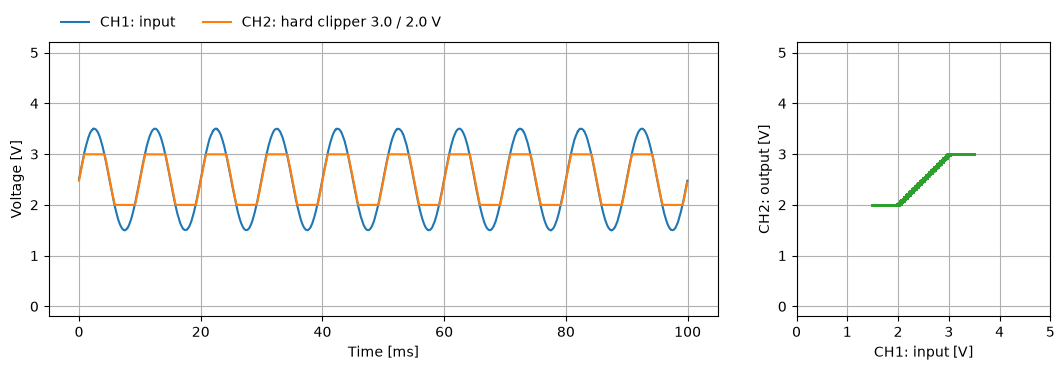

In [7]:
LOWER = 2.0   # [V]

lab.fg.sine(100, 1.0)
lab.mimic.clipper(3.0, LOWER)
t, ch1, ch2 = lab.scope.capture(2000)
a = harmonics(ch2, 100, 1 / (t[1] - t[0]))
print(f"2nd {a[1] * 1e3:.1f} mV, 3rd {a[2] * 1e3:.1f} mV, mean {ch2.mean():.3f} V")
scope_xy(t, ch1, ch2, f"hard clipper 3.0 / {LOWER} V")

### 3. 三角波から正弦波を作る

ソフトクリッパに三角波を入れると、角が丸められて正弦波に近い形になります。関数発生器の IC が正弦波を作るのに使う方法です。正弦波との差(当てはめた正弦波からのずれの実効値)を見ます。
<details><summary>ヒント</summary>

`AMP`(三角波の振幅)を 0.5 → 0.65 → 0.75 → 0.9 と変えてみましょう。制限 3.0 / 2.0 V(中心から 0.5 V)のソフトクリッパは、中心から 0.75 V(1.5 倍)で制限に届きます。三角波の山がちょうどそこに来る 0.75 V 前後で、正弦波とのずれがいちばん小さくなります(約 1 %)。小さいと三角波のまま、大きいと山が平らになります。

</details>

difference from a sine: 1.2 % (rms)


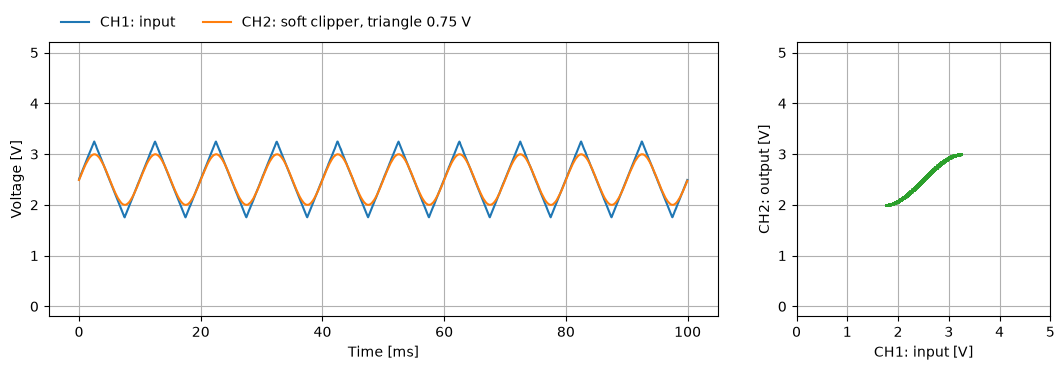

In [8]:
AMP = 0.75   # [V]

lab.fg.triangle(100, AMP)
lab.mimic.soft_clipper(3.0, 2.0)
t, ch1, ch2 = lab.scope.capture(2000)
a, p, c = fit_sine(t, ch2, 100)
fit = c + a * np.sin(2 * np.pi * 100 * t + np.radians(p))
print(f"difference from a sine: {np.sqrt(np.mean((ch2 - fit) ** 2)) / (a / np.sqrt(2)) * 100:.1f} % (rms)")
scope_xy(t, ch1, ch2, f"soft clipper, triangle {AMP} V")

## まとめ

- クリッパは、入力を lower〜upper の範囲に制限する。ダイオードとバイアスの電圧で作る。
- 理想のダイオード(オペアンプで補った回路)ならハードクリッパ、実際のダイオードの指数関数的な特性ならソフトクリッパ。
- 切り取ると高調波(ひずみ)が出る。上下対称なら奇数次、非対称なら偶数次も出る。ソフトのほうが高い次数の高調波が小さい。
- Mimic では `clipper(upper, lower)`、`soft_clipper(upper, lower)`。


最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [9]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()